**CS 4140 – Deep Learning · L11 · Debugging models and checking experiments** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L11_debugging/L11_debugging_and_experiments.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L11_debugging"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 11 · Debugging Models and Checking Experiments

**It runs. It's wrong. Now what?**

This notebook goes with the Feb 5 lecture. It has four parts:

* **Part A · The notebook that lies.** The familiar Fashion-MNIST CNN, written by a student with help from an AI assistant. It runs without a single error or warning, and it is wrong.
* **Part B · The debugging ladder.** Seven cheap checks, each with an answer we can predict before we run it. Each rung exposes a different problem.
* **Part C · Checking experiments.** Run records, seeds, and one controlled comparison: was the student's "upgrade" worth it?
* **Part D · The checklist** for your project (Deliverable 2) and for Coding Challenge 1.

**How to run it**

* `CLASS_MODE = True` (default): loads the saved results in `results.json` and the saved weights in `weights/`. The checks in Part B are cheap and run live. About 30 s on a laptop CPU.
* `CLASS_MODE = False`: re-runs every experiment and rewrites `results.json`, `weights/` and `runs/`. About 45 min on a 2-core CPU.
* The first run downloads Fashion-MNIST (about 30 MB) into `data/`.

The spoilers (the list of planted bugs) are in the appendix at the end. Try the ladder first.

In [1]:
CLASS_MODE = True          # True: load saved results (fast).  False: re-run everything (~45 min on a 2-core CPU).

import json, math, os, platform, subprocess, time, copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from torchvision.transforms import v2 as T

torch.set_num_threads(1)                                   # small model: one thread + one data worker is fastest on a 2-core CPU
NUM_WORKERS = 1 if platform.system() == 'Linux' else 0     # worker processes are fragile on Windows/macOS notebooks
HERE = Path('.')
RESULTS_FILE, WEIGHTS, RUNS = HERE / 'results.json', HERE / 'weights', HERE / 'runs'
CODE_VERSION = 'L12-bughunt-v1'

CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
MEAN, STD = 0.2860, 0.3530            # Fashion-MNIST pixel mean and standard deviation (on the 0-1 scale)
N_TRAIN, N_VAL = 20_000, 5_000        # a 20k training subset keeps CPU runs short
EPOCHS, BATCH, LR = 8, 64, 1e-3

# One fixed split of the 60k training images. The official 10k test set stays sealed until the very end.
_perm = np.random.default_rng(1234).permutation(60_000)
TRAIN_IDX = _perm[:N_TRAIN].tolist()
VAL_IDX = _perm[50_000:50_000 + N_VAL].tolist()

if CLASS_MODE:
    R = json.loads(RESULTS_FILE.read_text())
    print('Class mode: loaded', RESULTS_FILE, '| saved on', R['meta']['saved'])
else:
    R = {'meta': {}, 'runs': {}}
    WEIGHTS.mkdir(exist_ok=True); RUNS.mkdir(exist_ok=True)
    print('Full mode: every experiment will be re-run')
print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| python', platform.python_version())

Class mode: loaded results.json | saved on 2026-10-21 16:01
torch 2.14.1+cpu | torchvision 0.29.1+cpu | python 3.13.16


### The familiar training loop (Jan 20) and an evaluation helper

Same loop as always: forward, loss, `zero_grad`, `backward`, `step`. It records the per-epoch training and validation loss and accuracy (and, if asked, every step's loss).

In [2]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    tot, correct, loss_sum = 0, 0, 0.0
    for x, y in loader:
        out = model(x)
        loss_sum += loss_fn(out, y).item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
        tot += len(y)
    model.train()
    return loss_sum / tot, correct / tot


def fit(model, optimizer, loss_fn, train_loader, val_loader, epochs,
        scheduler=None, scheduler_every='epoch', log_steps=False, verbose=True):
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'step_loss', 'lr']}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            out = model(x)
            loss = loss_fn(out, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            if scheduler is not None and scheduler_every == 'batch':
                scheduler.step()
            loss_sum += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
            if log_steps:
                hist['step_loss'].append(round(loss.item(), 5))
                hist['lr'].append(optimizer.param_groups[0]['lr'])
        if scheduler is not None and scheduler_every == 'epoch':
            scheduler.step()
        vl, va = evaluate(model, val_loader, loss_fn)
        hist['train_loss'].append(loss_sum / n); hist['train_acc'].append(correct / n)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if verbose:
            print(f'epoch {epoch}: train loss {loss_sum/n:.3f} acc {correct/n:.1%} | '
                  f'val loss {vl:.3f} acc {va:.1%}   ({time.time()-t0:.0f} s)')
    return hist

---
## Part A · The notebook that lies

Read the next three cells like a reviewer. They are what the student submitted. Nothing in them crashes.

In [3]:
# ---- Student cell 1: data ------------------------------------------------------------
train_tf = T.Compose([
    T.RandomResizedCrop(28),                            # augmentation: random crops
    T.ToImage(), T.ToDtype(torch.float32, scale=True),
    T.Normalize((0.2860,), (0.3530,)),                  # Fashion-MNIST mean and std
])
eval_tf = T.Compose([
    T.ToImage(), T.ToDtype(torch.float32, scale=True),
    T.Normalize((0.5,), (0.5,)),
])
full_train = datasets.FashionMNIST('data', train=True, download=True, transform=train_tf)
full_val = datasets.FashionMNIST('data', train=True, download=True, transform=eval_tf)
train_set, val_set = Subset(full_train, TRAIN_IDX), Subset(full_val, VAL_IDX)
print(len(train_set), 'training images |', len(val_set), 'validation images')

20000 training images | 5000 validation images


In [4]:
# ---- Student cell 2: model -----------------------------------------------------------
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 7 * 7, 10),
            nn.Softmax(dim=1))                          # so the outputs are probabilities

    def forward(self, x):
        return self.head(self.features(x))

In [5]:
# ---- Student cell 3: train -----------------------------------------------------------
torch.manual_seed(0)
model = SmallCNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
train_loader = DataLoader(train_set, batch_size=64, shuffle=True,
                          generator=torch.Generator().manual_seed(0),
                          num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
val_loader = DataLoader(val_set, batch_size=500)

if CLASS_MODE:
    history = R['runs']['A_student']['hist']
    for e, (tl, ta, vl, va) in enumerate(zip(history['train_loss'], history['train_acc'],
                                             history['val_loss'], history['val_acc']), 1):
        print(f'epoch {e}: train loss {tl:.3f} acc {ta:.1%} | val loss {vl:.3f} acc {va:.1%}   (saved run)')
else:
    history = fit(model, optimizer, loss_fn, train_loader, val_loader, epochs=8)
    torch.save(model.state_dict(), WEIGHTS / 'A_student.pt')
print(f"\nValidation accuracy: {history['val_acc'][-1]:.1%}")

epoch 1: train loss 2.013 acc 44.9% | val loss 1.877 acc 59.0%   (saved run)
epoch 2: train loss 1.900 acc 56.3% | val loss 1.854 acc 60.6%   (saved run)
epoch 3: train loss 1.866 acc 59.7% | val loss 1.751 acc 71.4%   (saved run)
epoch 4: train loss 1.846 acc 61.7% | val loss 1.795 acc 66.6%   (saved run)
epoch 5: train loss 1.834 acc 62.8% | val loss 1.769 acc 69.0%   (saved run)
epoch 6: train loss 1.822 acc 64.1% | val loss 1.737 acc 72.5%   (saved run)
epoch 7: train loss 1.820 acc 64.2% | val loss 1.719 acc 74.7%   (saved run)
epoch 8: train loss 1.810 acc 65.2% | val loss 1.709 acc 75.6%   (saved run)

Validation accuracy: 75.6%


**No error. No warning.** The student's report says: *"Our CNN reaches about 76% on Fashion-MNIST; the dataset is harder than it looks."*

Is 76% good? We can't tell without **baselines**: the numbers that dumb or simple models get on the same split.

In [6]:
def baseline_runs():
    """Chance, majority class, a linear model on raw pixels, and the Jan 20 MLP: same split, same 8 epochs."""
    clean_tf = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize((MEAN,), (STD,))])
    tr = Subset(datasets.FashionMNIST('data', train=True, transform=clean_tf), TRAIN_IDX)
    va = Subset(datasets.FashionMNIST('data', train=True, transform=clean_tf), VAL_IDX)
    y_tr = np.array(datasets.FashionMNIST('data', train=True).targets)[TRAIN_IDX]
    y_va = np.array(datasets.FashionMNIST('data', train=True).targets)[VAL_IDX]
    out = {'chance': 0.1, 'majority': float(np.mean(y_va == np.bincount(y_tr).argmax()))}
    for name, net in [('linear', nn.Sequential(nn.Flatten(), nn.Linear(784, 10))),
                      ('mlp_jan20', nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10)))]:
        torch.manual_seed(0)
        opt = torch.optim.Adam(net.parameters(), lr=LR)
        h = fit(net, opt, nn.CrossEntropyLoss(),
                DataLoader(tr, batch_size=BATCH, shuffle=True, generator=torch.Generator().manual_seed(0)),
                DataLoader(va, batch_size=500), EPOCHS, verbose=False)
        out[name] = h['val_acc'][-1]
    return out

if not CLASS_MODE:
    R['baselines'] = baseline_runs()
for k, v in R['baselines'].items():
    print(f'{k:>10s}: {v:.1%}')
print(f"{'student CNN':>10s}: {history['val_acc'][-1]:.1%}   <- loses to a linear model on raw pixels")

    chance: 10.0%
  majority: 10.0%
    linear: 85.2%
 mlp_jan20: 87.3%
student CNN: 75.6%   <- loses to a linear model on raw pixels


A CNN that loses to a linear model on raw pixels is not "untuned". **It is broken.** That is the alarm. Now we find out why, without guessing.

---
## Part B · The debugging ladder

| Rung | Check | What we expect |
|---|---|---|
| 1 | Look at the batch the model actually sees | Recognizable garments with correct labels |
| 2 | Compare training and validation inputs | The same numbers for the same kind of image |
| 3 | Loss at initialization | About ln 10 = 2.303 for 10 balanced classes |
| 4 | Overfit one tiny batch | Loss → about 0 on 32 images |
| 5 | Gradients **and** updates, layer by layer | Every layer receives a gradient and moves |
| 6 | Read the learning curves | Shapes we can explain |
| 7 | Inspect the mistakes | Mistakes that make sense |

Rules: one change at a time; predict the answer before running the check; write down what you found.

### The same notebook, with each bug behind a switch

To measure things fairly, the next cell rebuilds the student's notebook so that each suspicious line can be switched on or off. With all switches on it is exactly Part A.

In [7]:
STUDENT = {'crop': True, 'eval_norm': 'half', 'softmax': True}    # the student's notebook (Part A)
FIXED = {'crop': False, 'eval_norm': False, 'softmax': False}


def make_transforms(b):
    if b['crop'] == 'none':
        crop = []                                                          # no augmentation (field guide)
    elif b['crop']:
        crop = [T.RandomResizedCrop(28)]                                   # ImageNet default: keeps 8-100% of the area
    else:
        crop = [T.RandomResizedCrop(28, scale=(0.8, 1.0))]                 # a crop that keeps the garment
    train_tf = T.Compose(crop + [T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize((MEAN,), (STD,))])
    to_float = [T.ToImage(), T.ToDtype(torch.float32, scale=True)]
    if b['eval_norm'] == 'half':
        eval_tf = T.Compose(to_float + [T.Normalize((0.5,), (0.5,))])     # constants copied from a tutorial
    elif b['eval_norm'] == 'missing':
        eval_tf = T.Compose(to_float)                                      # Normalize forgotten (field guide)
    else:
        eval_tf = T.Compose(to_float + [T.Normalize((MEAN,), (STD,))])     # same as training
    return train_tf, eval_tf


def make_sets(b, n_train=N_TRAIN, sort_by_class=False):
    train_tf, eval_tf = make_transforms(b)
    idx = TRAIN_IDX[:n_train]
    if sort_by_class:                                  # how ImageFolder delivers data: class by class
        targets = datasets.FashionMNIST('data', train=True).targets
        idx = sorted(idx, key=lambda i: (int(targets[i]), i))
    tr = Subset(datasets.FashionMNIST('data', train=True, transform=train_tf), idx)
    va = Subset(datasets.FashionMNIST('data', train=True, transform=eval_tf), VAL_IDX)
    return tr, va


class Net(nn.Module):
    """SmallCNN with switchable softmax; head='small' (Linear 1568->10) or 'wide' (1568->128->10)."""
    def __init__(self, softmax=False):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, 10), *([nn.Softmax(dim=1)] if softmax else []))

    def forward(self, x):
        return self.head(self.features(x))


def wide_head(softmax=False):
    return nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
                         *([nn.Softmax(dim=1)] if softmax else []))


def build(b, seed=0, wide=False, stale=False):
    """Mirrors the notebook cells: model, (upgrade cell), optimizer.
    stale=True builds the optimizer BEFORE the upgrade cell replaces the head."""
    torch.manual_seed(seed)
    model = Net(softmax=b['softmax'])
    if stale:
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    if wide:
        model.head = wide_head(softmax=b['softmax'])         # the upgrade cell
    if not stale:
        optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    return model, optimizer


def git_commit():
    try:
        return subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD'], text=True,
                                       stderr=subprocess.DEVNULL).strip()
    except Exception:
        return 'not under git (demo)'


def record_run(name, config, hist, purpose):
    """One folder per run: what you ran, why, with which seed and code, and what came out.
    Same idea as src/run_record.py in the CS 4140 project template."""
    folder = RUNS / f"{time.strftime('%Y%m%d-%H%M%S')}_{name}"
    folder.mkdir(parents=True, exist_ok=True)
    meta = {'name': name, 'purpose': purpose, 'config': config, 'seed': config.get('seed'),
            'code_version': CODE_VERSION, 'commit': git_commit(),
            'data': {'dataset': 'Fashion-MNIST', 'split_seed': 1234, 'n_train': config.get('n_train', N_TRAIN), 'n_val': N_VAL},
            'env': {'python': platform.python_version(), 'torch': torch.__version__,
                    'torchvision': torchvision.__version__, 'device': 'cpu', 'platform': platform.platform()},
            'started': time.strftime('%Y-%m-%d %H:%M:%S')}
    (folder / 'config.json').write_text(json.dumps(meta, indent=2))
    (folder / 'metrics.json').write_text(json.dumps({'final_val_acc': hist['val_acc'][-1],
                                                     'final_val_loss': hist['val_loss'][-1], 'history': hist}))
    return folder


def run(name, b, seed=0, wide=False, stale=False, epochs=EPOCHS, n_train=N_TRAIN,
        sort_by_class=False, shuffle=True, log_steps=False, purpose='', save_weights=False,
        scheduler=None, scheduler_every='epoch'):
    tr, va = make_sets(b, n_train, sort_by_class)
    model, optimizer = build(b, seed, wide, stale)
    sched = None
    if scheduler == 'decay_3pct_each_epoch':
        sched = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.97)    # meant: 3% smaller every epoch
    tl = DataLoader(tr, batch_size=BATCH, shuffle=shuffle, generator=torch.Generator().manual_seed(seed),
                    num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0)
    vl = DataLoader(va, batch_size=500)
    print(f'--- {name}')
    hist = fit(model, optimizer, nn.CrossEntropyLoss(), tl, vl, epochs, scheduler=sched,
               scheduler_every=scheduler_every, log_steps=log_steps)
    config = {'bugs': b, 'seed': seed, 'head': 'wide' if wide else 'small', 'optimizer_built': 'before upgrade' if stale else 'last',
              'epochs': epochs, 'batch': BATCH, 'lr': LR, 'optimizer': 'Adam', 'n_train': n_train,
              'sort_by_class': sort_by_class, 'shuffle': shuffle, 'scheduler': scheduler, 'scheduler_every': scheduler_every}
    folder = record_run(name, config, hist, purpose)
    R['runs'][name] = {'config': config, 'hist': hist, 'final_val_acc': hist['val_acc'][-1], 'run_folder': folder.name}
    if save_weights:
        torch.save(model.state_dict(), WEIGHTS / f'{name}.pt')
    return model, hist


def show_grid(images, titles, ncols=8, size=1.4, suptitle=None):
    n = len(images); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.18))
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, img, t in zip(np.ravel(axes), images, titles):
        ax.imshow(img, cmap='gray_r'); ax.set_title(t, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout(); plt.show()

In [8]:
# The engine reproduces Part A exactly (same seed, same order of random draws).
if not CLASS_MODE:
    _, h = run('A_engine_check', STUDENT, seed=0, purpose='engine == Part A?')
    assert abs(h['val_acc'][-1] - history['val_acc'][-1]) < 1e-9, 'engine does not reproduce Part A'
    R['runs']['A_student'] = {'hist': history, 'final_val_acc': history['val_acc'][-1], 'config': R['runs']['A_engine_check']['config']}
print('Part A validation accuracy:', f"{R['runs']['A_student']['final_val_acc']:.2%}")

Part A validation accuracy: 75.56%


### Rung 1 · Look at the batch the model actually sees

Not the files on disk: the tensors **after** the whole pipeline, with their labels. Prediction: 32 recognizable garments, each with the right label.

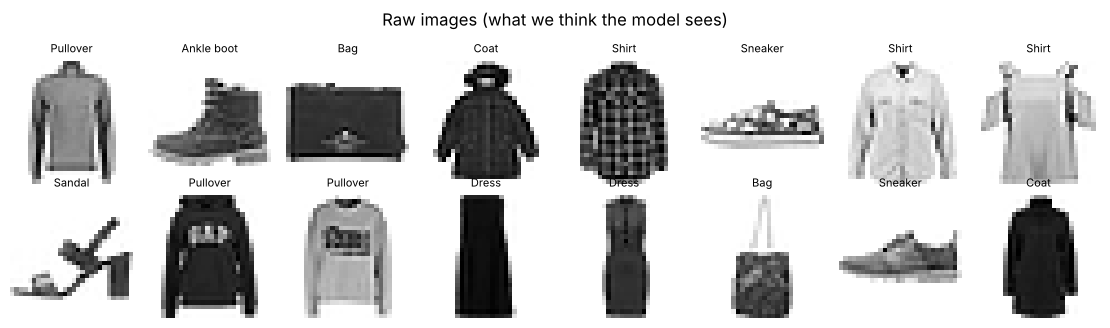

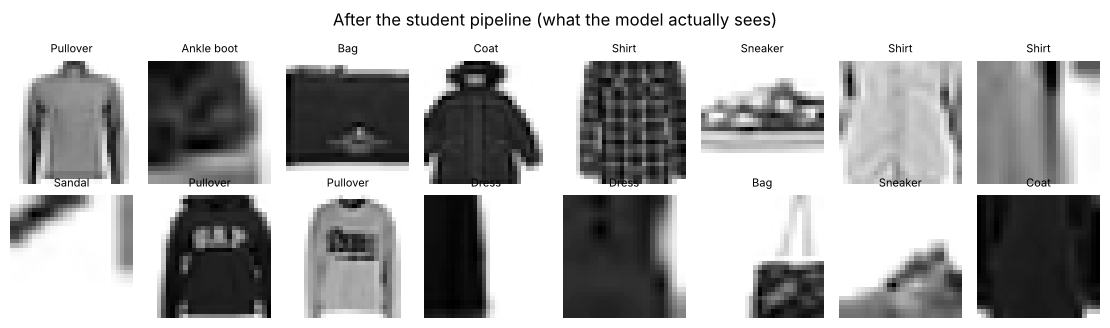

In [9]:
torch.manual_seed(1)
tr_student, _ = make_sets(STUDENT)
tr_fixed, _ = make_sets({**STUDENT, 'crop': False})
raw = datasets.FashionMNIST('data', train=True)
idx = list(range(16))
show_grid([raw.data[TRAIN_IDX[i]] for i in idx], [CLASSES[raw.targets[TRAIN_IDX[i]]] for i in idx], suptitle='Raw images (what we think the model sees)')
show_grid([tr_student[i][0][0] for i in idx], [CLASSES[tr_student[i][1]] for i in idx], suptitle='After the student pipeline (what the model actually sees)')

**Finding.** Many "images" are blurry close-ups of a collar, a sleeve or a sole. `T.RandomResizedCrop(28)` uses ImageNet defaults: it keeps a random **8% to 100%** of the image area and stretches it back to 28×28. On 28×28 garments that often removes the evidence for the label: is a zoomed-in sleeve a T-shirt, a shirt, a pullover or a coat?

**Fix.** Keep crops that keep the garment: `T.RandomResizedCrop(28, scale=(0.8, 1.0))`.

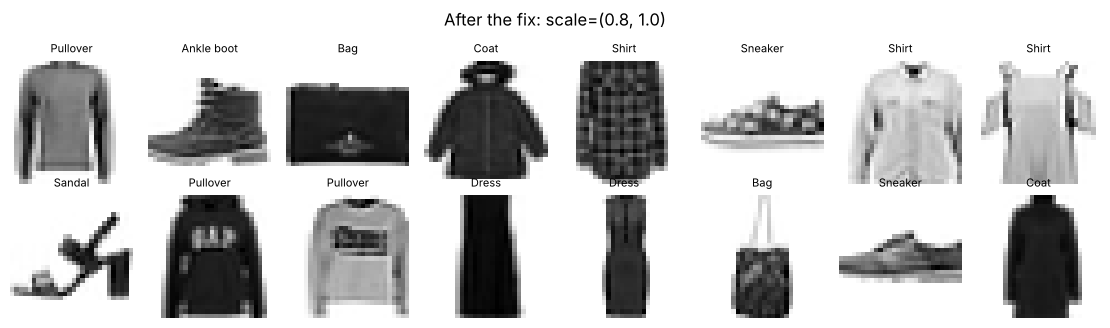

default crops: median area kept 49%; 50% keep less than half the image, 20% less than a quarter


In [10]:
show_grid([tr_fixed[i][0][0] for i in idx], [CLASSES[tr_fixed[i][1]] for i in idx], suptitle='After the fix: scale=(0.8, 1.0)')

# How much of the image do 10,000 default crops keep?
torch.manual_seed(3)
crop = T.RandomResizedCrop(28)
areas = np.array([(lambda p: p['height'] * p['width'] / 784)(crop.make_params([torch.zeros(1, 28, 28)]))
                  for _ in range(10_000)])
print(f'default crops: median area kept {np.median(areas):.0%}; '
      f'{np.mean(areas < 0.5):.0%} keep less than half the image, {np.mean(areas < 0.25):.0%} less than a quarter')
if not CLASS_MODE:
    R.setdefault('checks', {})['crop_area'] = {'median': float(np.median(areas)), 'below_half': float(np.mean(areas < 0.5)),
                                               'below_quarter': float(np.mean(areas < 0.25))}

### Rung 2 · Compare training and validation inputs

The model learned in one "language" of numbers; it must be examined in the same one. Prediction: similar statistics, and the same value for the same pixel (a black background pixel, 0 on disk, should map to the same number in both).

In [11]:
def input_stats(dataset, n=512):
    x = torch.stack([dataset[i][0] for i in range(n)])
    return {'mean': x.mean().item(), 'std': x.std().item(), 'min': x.min().item(), 'max': x.max().item()}

_, va_student = make_sets(STUDENT)
torch.manual_seed(2)
stats = {'training (crop fixed)': input_stats(tr_fixed), 'validation (student)': input_stats(va_student)}
for k, s in stats.items():
    print(f"{k:>22s}: mean {s['mean']:+.3f}  std {s['std']:.3f}  min {s['min']:+.3f}  max {s['max']:+.3f}")
print(f'\nA background pixel (0 on disk): training {(0 - MEAN) / STD:+.3f}, validation {(0 - 0.5) / 0.5:+.3f}')
print(f'A white pixel (1 on disk):      training {(1 - MEAN) / STD:+.3f}, validation {(1 - 0.5) / 0.5:+.3f}')
if not CLASS_MODE:
    R['checks']['input_stats'] = stats

 training (crop fixed): mean +0.085  std 0.995  min -0.810  max +2.023
  validation (student): mean -0.444  std 0.691  min -1.000  max +1.000

A background pixel (0 on disk): training -0.810, validation -1.000
A white pixel (1 on disk):      training +2.023, validation +1.000


**Finding.** Training images are normalized with the Fashion-MNIST statistics (0.2860, 0.3530); validation images with (0.5, 0.5), copied from a tutorial. Every validation pixel is shifted and squeezed: the background is −0.81 in training and −1.00 in validation; the brightest pixel is +2.02 versus +1.00.

**Fix.** One preprocessing definition, used by both pipelines: `T.Normalize((0.2860,), (0.3530,))` in `eval_tf` too.

### Rung 3 · Check the loss at initialization

Before any training, a 10-class network should be unsure: about 1/10 for every class, so the loss should be about −ln(1/10) = ln 10 = **2.303**.

In [12]:
_, va_fixed = make_sets({**STUDENT, 'crop': False, 'eval_norm': False})
xv, yv = next(iter(DataLoader(va_fixed, batch_size=500)))
init = {}
for label, sm in [('student model (softmax in head)', True), ('model without the softmax', False)]:
    torch.manual_seed(0); m = Net(softmax=sm)
    with torch.no_grad():
        init[label] = nn.CrossEntropyLoss()(m(xv), yv).item()
torch.manual_seed(0); m = Net()
with torch.no_grad():
    init['raw 0-255 pixels (no scaling)'] = nn.CrossEntropyLoss()(m(xv * STD * 255 + MEAN * 255), yv).item()
for k, v in init.items():
    print(f'{k:>32s}: {v:.3f}')
print(f"{'expected':>32s}: {math.log(10):.3f}")
if not CLASS_MODE:
    R['checks']['init_loss'] = init

 student model (softmax in head): 2.301
       model without the softmax: 2.294
   raw 0-255 pixels (no scaling): 10.891
                        expected: 2.303


**Finding.** The student's model passes: 2.30. A failing case looks like the last line (unscaled inputs: an overconfident network at step 0).

A passing check is still evidence: it rules out a wrong number of classes, wildly confident initial outputs, and broken targets. But **a pass is not a proof**. Keep this 2.303 in mind for the next rung.

### Rung 4 · Overfit one tiny batch

32 training images, the same 32 every step, no augmentation, no regularization. A working network with 20,490 parameters should memorize them: loss → about 0, accuracy → 100%. If it can't, nothing else matters yet.

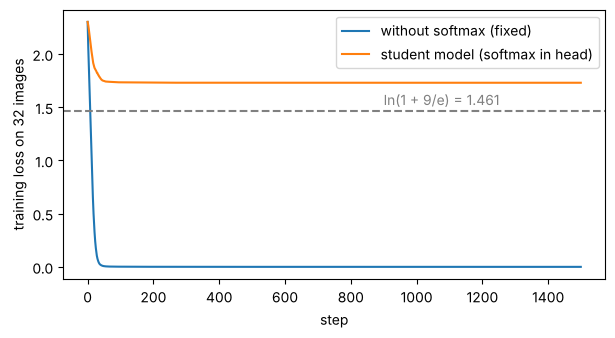

 student: loss after 50 steps 1.7462, after 1500 steps 1.7301; accuracy 72%
   fixed: loss after 50 steps 0.0070, after 1500 steps 0.0000; accuracy 100%

student model, image by image: 23 right, each costing 1.461; 9 wrong, costing 2.417 on average
median top probability 0.99999: the outputs are (almost) one-hot, so the softmax is saturated
size of the gradient: 0.171 at step 1, 0.000051 at step 1500 (3,378x smaller)


In [13]:
_, _eval_tf = make_transforms(FIXED)
tiny_set = Subset(datasets.FashionMNIST('data', train=True, transform=_eval_tf), TRAIN_IDX[:32])   # 32 training images, no augmentation

def tiny_batch_test(softmax, steps=1500, n=32, seed=0):
    xt, yt = next(iter(DataLoader(tiny_set, batch_size=n)))
    torch.manual_seed(seed)
    m = Net(softmax=softmax)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    losses, accs, gnorms = [], [], []
    for s in range(steps):
        out = m(xt); loss = nn.CrossEntropyLoss()(out, yt)
        opt.zero_grad(); loss.backward()
        gnorms.append(float(sum(p.grad.norm() ** 2 for p in m.parameters()) ** 0.5))   # size of the whole gradient
        opt.step()
        losses.append(round(loss.item(), 6)); accs.append((out.argmax(1) == yt).float().mean().item())
    with torch.no_grad():
        out = m(xt)
        per_image = nn.CrossEntropyLoss(reduction='none')(out, yt)
    return {'loss': losses, 'acc': accs, 'grad_norm': gnorms, 'final_per_image_loss': per_image.tolist(),
            'final_correct': (out.argmax(1) == yt).tolist(), 'final_max_prob': torch.softmax(out, 1).max(1).values.tolist() if not softmax else out.max(1).values.tolist()}

if CLASS_MODE:
    tiny = R['checks']['tiny_batch']
else:
    tiny = {'student': tiny_batch_test(True), 'fixed': tiny_batch_test(False)}
    R['checks']['tiny_batch'] = tiny
FLOOR = math.log(1 + 9 / math.e)
plt.figure(figsize=(7, 3.5))
plt.plot(tiny['fixed']['loss'], label='without softmax (fixed)')
plt.plot(tiny['student']['loss'], label='student model (softmax in head)')
plt.axhline(FLOOR, ls='--', c='gray'); plt.text(900, FLOOR + 0.06, f'ln(1 + 9/e) = {FLOOR:.3f}', color='gray')
plt.xlabel('step'); plt.ylabel('training loss on 32 images'); plt.legend(); plt.show()
for k in ['student', 'fixed']:
    print(f"{k:>8s}: loss after 50 steps {tiny[k]['loss'][49]:.4f}, after {len(tiny[k]['loss'])} steps {tiny[k]['loss'][-1]:.4f}; accuracy {tiny[k]['acc'][-1]:.0%}")
st = tiny['student']
per, ok = np.array(st['final_per_image_loss']), np.array(st['final_correct'])
print(f"\nstudent model, image by image: {ok.sum()} right, each costing {per[ok].mean():.3f}; {(~ok).sum()} wrong, costing {per[~ok].mean():.3f} on average")
print(f"median top probability {np.median(st['final_max_prob']):.5f}: the outputs are (almost) one-hot, so the softmax is saturated")
print(f"size of the gradient: {st['grad_norm'][0]:.3f} at step 1, {st['grad_norm'][-1]:.6f} at step {len(st['grad_norm'])} "
      f"({st['grad_norm'][0] / st['grad_norm'][-1]:,.0f}x smaller)")

**Finding.** The student model fails the test: it cannot memorize 32 images. Its loss gets stuck near 1.73 and never gets below a line at **1.461**. That number is not a coincidence.

The head ends in `nn.Softmax`, so the network outputs probabilities between 0 and 1. `nn.CrossEntropyLoss` expects raw scores (logits) and applies a softmax **again**. The best the network can ever output is (1, 0, …, 0), and the loss of that is

−ln( e¹ / (e¹ + 9·e⁰) ) = ln(1 + 9/e) = 1.461.

A confidently **wrong** one-hot output costs ln(e + 9) = 2.461. The student model's outputs have saturated to one-hot vectors: every right answer costs 1.461, every wrong one about 2.46, and the average is the 1.73 plateau. A saturated softmax is flat, so the gradient all but vanishes and the wrong answers can never be corrected.

Why did rung 3 miss it? At initialization the probabilities are all about 0.1, and a softmax of ten equal numbers is uniform again: 2.303 either way.

**Fix.** Delete `nn.Softmax(dim=1)`. `CrossEntropyLoss` wants logits; take `softmax` only when you need probabilities for display.

### Scoreboard: fix one thing at a time and re-measure

In [14]:
if not CLASS_MODE:
    run('A1_fix_crop', {**STUDENT, 'crop': False}, purpose='ladder: rung 1 fix')
    run('A2_fix_crop_norm', {**STUDENT, 'crop': False, 'eval_norm': False}, purpose='ladder: rungs 1-2 fixed')
    run('A3_fixed', FIXED, save_weights=True, purpose='ladder: rungs 1-4 fixed (small head, seed 0)')
    run('only_crop', {**FIXED, 'crop': True}, purpose='cost of the crop bug alone')
    run('only_norm', {**FIXED, 'eval_norm': 'half'}, purpose='cost of the normalization bug alone')
    run('only_softmax', {**FIXED, 'softmax': True}, purpose='cost of the softmax bug alone')

print(f'Fixing in ladder order (validation accuracy after {EPOCHS} epochs):')
for name, label in [('A_student', 'student notebook'), ('A1_fix_crop', '+ fix the crop'),
                    ('A2_fix_crop_norm', '+ fix the normalization'), ('A3_fixed', '+ remove the softmax')]:
    print(f"  {label:<28s} {R['runs'][name]['final_val_acc']:.1%}")
print('\nEach bug alone in the fixed notebook:')
for name, label in [('only_crop', 'only the crop'), ('only_norm', 'only the normalization'), ('only_softmax', 'only the softmax')]:
    cost = 100 * (R['runs']['A3_fixed']['final_val_acc'] - R['runs'][name]['final_val_acc'])
    print(f"  {label:<28s} {R['runs'][name]['final_val_acc']:.1%}   (costs {cost:.1f} points)")

Fixing in ladder order (validation accuracy after 8 epochs):
  student notebook             75.6%
  + fix the crop               80.2%
  + fix the normalization      82.9%
  + remove the softmax         88.0%

Each bug alone in the fixed notebook:
  only the crop                83.3%   (costs 4.7 points)
  only the normalization       82.7%   (costs 5.3 points)
  only the softmax             82.9%   (costs 5.2 points)


### Rung 5 · Gradients **and** updates: does every layer learn?

The notebook now reaches about 88%. The student asks an AI assistant how to improve it, and pastes its suggestion as a new cell **below** the optimizer cell:

```python
# AI suggestion: a hidden layer in the head gives the classifier more capacity
model.head = nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
```

Validation accuracy drops from about 88% to about 77%. Is a wider head a bad idea? Check every layer: after 100 steps, does each one have a gradient, and did its weights actually move?

In [15]:
def layer_report(model, optimizer, steps=100, seed=0):
    tr, _ = make_sets(FIXED)
    w0 = {n: p.detach().clone() for n, p in model.named_parameters() if n.endswith('weight')}
    loader = DataLoader(tr, batch_size=BATCH, shuffle=True, generator=torch.Generator().manual_seed(seed))
    batches = (b for _ in range(10**6) for b in loader)                  # repeat the loader if needed
    for _ in range(steps):
        x, y = next(batches)
        loss = nn.CrossEntropyLoss()(model(x), y)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    rows = []
    for n, p in model.named_parameters():
        if n.endswith('weight'):
            rows.append({'layer': n, 'grad_norm': p.grad.norm().item(),
                         'moved': ((p.detach() - w0[n]).norm() / w0[n].norm()).item()})
    n_model = sum(p.numel() for p in model.parameters())
    n_opt = sum(p.numel() for g in optimizer.param_groups for p in g['params'])
    return {'rows': rows, 'n_model': n_model, 'n_optimizer': n_opt}

if CLASS_MODE:
    reports = R['checks']['layer_report']
else:
    reports = {'upgrade (optimizer built first)': layer_report(*build(FIXED, wide=True, stale=True)),
               'upgrade (optimizer built last)': layer_report(*build(FIXED, wide=True, stale=False))}
    R['checks']['layer_report'] = reports
for k, rep in reports.items():
    print(f"{k}: model has {rep['n_model']:,} parameters, the optimizer holds {rep['n_optimizer']:,}")
    for r in rep['rows']:
        print(f"   {r['layer']:<18s} gradient norm {r['grad_norm']:9.3f}   weights moved {r['moved']:7.2%}")

upgrade (optimizer built first): model has 206,922 parameters, the optimizer holds 20,490
   features.0.weight  gradient norm     0.164   weights moved  47.95%
   features.3.weight  gradient norm     0.318   weights moved 101.14%
   head.1.weight      gradient norm   196.581   weights moved   0.00%
   head.3.weight      gradient norm    56.984   weights moved   0.00%
upgrade (optimizer built last): model has 206,922 parameters, the optimizer holds 206,922
   features.0.weight  gradient norm     0.427   weights moved  15.64%
   features.3.weight  gradient norm     0.813   weights moved  49.25%
   head.1.weight      gradient norm     1.764   weights moved  82.75%
   head.3.weight      gradient norm     5.063   weights moved  24.27%


**Finding.** The new head gets a gradient (a large one, and it keeps growing: `optimizer.zero_grad()` only zeroes the parameters the optimizer knows), but its weights moved **0.00%**. The optimizer was built from the old model's parameters; the head that the upgrade cell created never reached it. The 20k-parameter optimizer is training a 207k-parameter network whose head is frozen at random.

**Fix.** Build the optimizer **last**, after every change to the model. (Transfer learning on Feb 24 replaces heads all the time.) Habit: *Restart & Run All* before you trust a number.

In [16]:
if not CLASS_MODE:
    run('B_upgrade_stale', FIXED, wide=True, stale=True, purpose='the AI upgrade pasted below the optimizer cell')
print(f"before the upgrade (small head):        {R['runs']['A3_fixed']['final_val_acc']:.1%}")
print(f"upgrade, optimizer built before it:     {R['runs']['B_upgrade_stale']['final_val_acc']:.1%}")

before the upgrade (small head):        88.0%
upgrade, optimizer built before it:     76.5%


Whether the wider head **itself** helps is a separate question, answered properly in Part C.

### Rung 6 · Read the learning curves

First the student's curves against the fixed ones; then a field guide of shapes, each produced by a real run of this network with one thing broken.

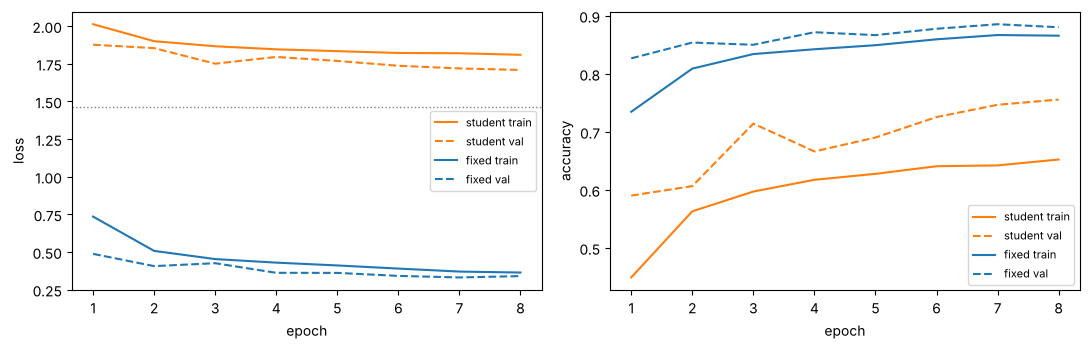

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ep = range(1, EPOCHS + 1)
for name, label, c in [('A_student', 'student', 'tab:orange'), ('A3_fixed', 'fixed', 'tab:blue')]:
    h = R['runs'][name]['hist']
    axes[0].plot(ep, h['train_loss'], c=c, label=f'{label} train'); axes[0].plot(ep, h['val_loss'], c=c, ls='--', label=f'{label} val')
    axes[1].plot(ep, h['train_acc'], c=c, label=f'{label} train'); axes[1].plot(ep, h['val_acc'], c=c, ls='--', label=f'{label} val')
axes[0].axhline(FLOOR, c='gray', lw=1, ls=':'); axes[0].set_ylabel('loss'); axes[1].set_ylabel('accuracy')
for a in axes: a.set_xlabel('epoch'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

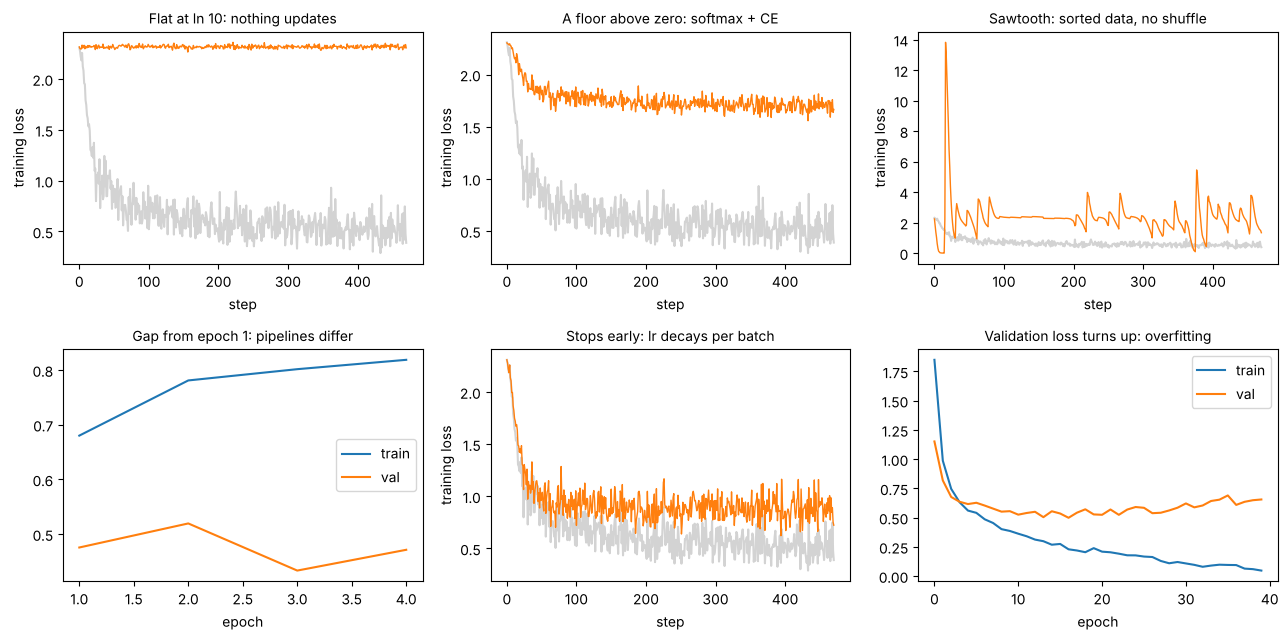

In [18]:
FG_N, FG_EPOCHS = 10_000, 3
if not CLASS_MODE:
    run('FG_healthy', FIXED, n_train=FG_N, epochs=FG_EPOCHS, log_steps=True, purpose='field guide: reference')
    # "Nothing updates": the model cell was re-run after the optimizer cell, so the optimizer holds the OLD model.
    tr, va = make_sets(FIXED, FG_N)
    torch.manual_seed(0); old = Net(); opt = torch.optim.Adam(old.parameters(), lr=LR); m = Net()
    h = fit(m, opt, nn.CrossEntropyLoss(), DataLoader(tr, batch_size=BATCH, shuffle=True, generator=torch.Generator().manual_seed(0)),
            DataLoader(va, batch_size=500), FG_EPOCHS, log_steps=True)
    record_run('FG_flat', {'seed': 0, 'note': 'model re-created after the optimizer', 'n_train': FG_N}, h, 'field guide: nothing updates')
    R['runs']['FG_flat'] = {'hist': h, 'final_val_acc': h['val_acc'][-1]}
    run('FG_floor', {**FIXED, 'softmax': True}, n_train=FG_N, epochs=FG_EPOCHS, log_steps=True, purpose='field guide: loss floor')
    run('FG_sorted', FIXED, n_train=FG_N, epochs=FG_EPOCHS, log_steps=True, sort_by_class=True, shuffle=False,
        purpose='field guide: data sorted by class, no shuffle')
    run('FG_gap', {**FIXED, 'eval_norm': 'missing'}, n_train=FG_N, epochs=FG_EPOCHS + 1, purpose='field guide: Normalize missing at evaluation')
    run('FG_sched', FIXED, n_train=FG_N, epochs=FG_EPOCHS, log_steps=True, scheduler='decay_3pct_each_epoch',
        scheduler_every='batch', purpose='field guide: scheduler stepped every batch')
    run('FG_overfit', {**FIXED, 'crop': 'none'}, n_train=1_000, epochs=40, wide=True, purpose='field guide: overfitting')

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
ref = R['runs']['FG_healthy']['hist']['step_loss']
panels = [('FG_flat', 'Flat at ln 10: nothing updates'), ('FG_floor', 'A floor above zero: softmax + CE'),
          ('FG_sorted', 'Sawtooth: sorted data, no shuffle'), ('FG_sched', 'Stops early: lr decays per batch')]
for ax, (name, title) in zip(axes.ravel()[[0, 1, 2, 4]], panels):
    ax.plot(ref, c='lightgray', label='healthy'); ax.plot(R['runs'][name]['hist']['step_loss'], c='tab:orange', lw=1, label=name)
    ax.set_title(title, fontsize=10); ax.set_xlabel('step'); ax.set_ylabel('training loss')
h = R['runs']['FG_gap']['hist']
axes[1, 0].plot(range(1, len(h['train_acc']) + 1), h['train_acc'], label='train'); axes[1, 0].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label='val')
axes[1, 0].set_title('Gap from epoch 1: pipelines differ', fontsize=10); axes[1, 0].set_xlabel('epoch'); axes[1, 0].legend()
h = R['runs']['FG_overfit']['hist']
axes[1, 2].plot(h['train_loss'], label='train'); axes[1, 2].plot(h['val_loss'], label='val')
axes[1, 2].set_title('Validation loss turns up: overfitting', fontsize=10); axes[1, 2].set_xlabel('epoch'); axes[1, 2].legend()
plt.tight_layout(); plt.show()

| Shape | What it usually means | First thing to check |
|---|---|---|
| Flat at ln(classes) | Nothing is updating | Does the optimizer hold the model's parameters? Is lr > 0? |
| Floor above zero | The loss can't reach zero | Softmax before `CrossEntropyLoss`; wrong targets; noisy labels |
| Sawtooth once per epoch | Batches are not mixed | `shuffle=True`; data sorted by class (ImageFolder!) |
| Gap from epoch 1 | Train and validation differ | The two pipelines; the split |
| Stops early, high | The learning rate died | `scheduler.step()` in the wrong loop |
| Validation loss turns up | Overfitting (Jan 29) | More data, regularization, early stopping |

### Rung 7 · Inspect the mistakes

With the fixed model: which classes are confused, and what do the most confident mistakes look like?

validation accuracy 88.0%
  Shirt        65.2%
  Coat         71.3%
  Pullover     84.4%
  T-shirt/top  85.3%
  Sneaker      90.8%
  Dress        92.9%
  Trouser      96.0%
  Bag          97.1%
  Ankle boot   97.1%
  Sandal       99.2%


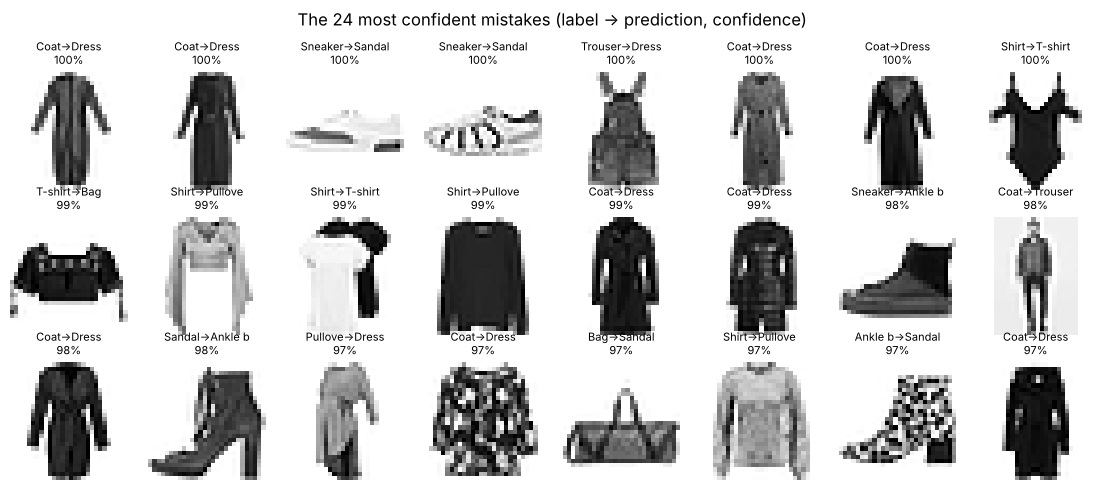

In [19]:
fixed_model = Net(); fixed_model.load_state_dict(torch.load(WEIGHTS / 'A3_fixed.pt'))
fixed_model.eval()
_, va_fixed = make_sets(FIXED)
loader = DataLoader(va_fixed, batch_size=500)
probs, ys = [], []
with torch.no_grad():
    for x, y in loader:
        probs.append(torch.softmax(fixed_model(x), 1)); ys.append(y)
probs, ys = torch.cat(probs), torch.cat(ys)
pred = probs.argmax(1)
cm = np.zeros((10, 10), int)
for t, p in zip(ys.tolist(), pred.tolist()):
    cm[t, p] += 1
per_class = cm.diagonal() / cm.sum(1)
print(f'validation accuracy {np.trace(cm) / cm.sum():.1%}')
for c in np.argsort(per_class):
    print(f'  {CLASSES[c]:<12s} {per_class[c]:.1%}')
wrong = (pred != ys).nonzero().ravel()
conf = probs[wrong, pred[wrong]]
order = wrong[conf.argsort(descending=True)][:24]
show_grid([va_fixed[i][0][0] * STD + MEAN for i in order.tolist()],
          [f'{CLASSES[ys[i]][:7]}→{CLASSES[pred[i]][:7]}\n{probs[i, pred[i]]:.0%}' for i in order.tolist()],
          suptitle='The 24 most confident mistakes (label → prediction, confidence)')
if not CLASS_MODE:
    R['checks']['mistakes'] = {'confusion': cm.tolist(), 'per_class': per_class.tolist(),
                               'top_confident': [{'val_pos': int(i), 'dataset_idx': int(VAL_IDX[i]), 'label': int(ys[i]),
                                                  'pred': int(pred[i]), 'conf': float(probs[i, pred[i]])} for i in order.tolist()]}

**Finding.** Shirts are the weak class, confused with T-shirts, pullovers and coats. Among the most confident mistakes, some are the model's fault, some are genuinely ambiguous at 28×28, and some look **mislabeled**. Each kind needs a different fix: better model or more data; clearer class definitions; or fixing the labels. Large benchmarks have the same problem: Northcutt, Athalye and Mueller (NeurIPS 2021) estimate that at least 3.3% of test labels across 10 popular datasets are wrong, and at least 6% in the ImageNet validation set.

---
## Part C · Checking experiments

The code is fixed. Was the AI's wider head worth it once the optimizer is built last? A fair answer needs:

* a **baseline**: the small head, same everything else;
* a **record** of every run: configuration, seed, code version, data split, environment, results (see `runs/`);
* **seeds**: one run is one sample of a random process;
* **one controlled comparison**: change only the head; pair the runs by seed.

The decision rule is written down **before** looking: *keep the wider head only if it wins on average and in at least 4 of 5 paired seeds.*

In [20]:
SEEDS = [0, 1, 2, 3, 4]
if not CLASS_MODE:
    R['runs']['small_s0'] = R['runs']['A3_fixed']
    for s in SEEDS[1:]:
        run(f'small_s{s}', FIXED, seed=s, purpose='controlled comparison: small head')
    for s in SEEDS:
        run(f'wide_s{s}', FIXED, seed=s, wide=True, save_weights=(s == 0), purpose='controlled comparison: wide head')
small = np.array([R['runs'][f'small_s{s}']['final_val_acc'] for s in SEEDS])
wide = np.array([R['runs'][f'wide_s{s}']['final_val_acc'] for s in SEEDS])
diff = wide - small
print('seed   small    wide    wide - small')
for s, a, b, d in zip(SEEDS, small, wide, diff):
    print(f'  {s}   {a:.2%}  {b:.2%}   {d:+.2%}')
print(f'mean   {small.mean():.2%}  {wide.mean():.2%}   {diff.mean():+.2%}  (sd of the differences {diff.std(ddof=1):.2%})')
print(f'spread across seeds: small {small.min():.2%}-{small.max():.2%}, wide {wide.min():.2%}-{wide.max():.2%}')
cross = (wide[:, None] - small[None, :]).ravel()
print(f'one run each, unpaired: the "gain" could be anything from {cross.min():+.2%} to {cross.max():+.2%}')
keep_wide = diff.mean() > 0 and (diff > 0).sum() >= 4
print('decision:', 'keep the wider head' if keep_wide else 'keep the small head (the upgrade is not clearly better)')
if not CLASS_MODE:
    R['comparison'] = {'seeds': SEEDS, 'small': small.tolist(), 'wide': wide.tolist(), 'diff': diff.tolist(),
                       'cross_min': float(cross.min()), 'cross_max': float(cross.max()), 'keep_wide': bool(keep_wide)}

seed   small    wide    wide - small
  0   88.02%  87.90%   -0.12%
  1   87.66%  87.56%   -0.10%
  2   88.16%  89.00%   +0.84%
  3   88.48%  88.16%   -0.32%
  4   88.10%  89.02%   +0.92%
mean   88.08%  88.33%   +0.24%  (sd of the differences 0.59%)
spread across seeds: small 87.66%-88.48%, wide 87.56%-89.02%
one run each, unpaired: the "gain" could be anything from -0.92% to +1.36%
decision: keep the small head (the upgrade is not clearly better)


### What one run record looks like

In [21]:
folder = RUNS / R['runs']['wide_s0']['run_folder']
print(folder)
print((folder / 'config.json').read_text() if folder.exists() else '(run folders are written in full mode)')

runs/20261021-155302_wide_s0
{
  "name": "wide_s0",
  "purpose": "controlled comparison: wide head",
  "config": {
    "bugs": {
      "crop": false,
      "eval_norm": false,
      "softmax": false
    },
    "seed": 0,
    "head": "wide",
    "optimizer_built": "last",
    "epochs": 8,
    "batch": 64,
    "lr": 0.001,
    "optimizer": "Adam",
    "n_train": 20000,
    "sort_by_class": false,
    "shuffle": true,
    "scheduler": null,
    "scheduler_every": "epoch"
  },
  "seed": 0,
  "code_version": "L12-bughunt-v1",
  "commit": "not under git (demo)",
  "data": {
    "dataset": "Fashion-MNIST",
    "split_seed": 1234,
    "n_train": 20000,
    "n_val": 5000
  },
  "env": {
    "python": "3.13.16",
    "torch": "2.14.1+cpu",
    "torchvision": "0.29.1+cpu",
    "device": "cpu",
    "platform": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39"
  },
  "started": "2026-10-21 15:53:02"
}


### Open the test set once

Only now, with the debugging and the decision done, the sealed test set is used, once, for the chosen configuration (seed 0).

In [22]:
chosen = 'wide_s0' if R['comparison']['keep_wide'] else 'A3_fixed'
if not CLASS_MODE:
    m = Net()
    if chosen.startswith('wide'):
        m.head = wide_head()
    m.load_state_dict(torch.load(WEIGHTS / f'{chosen}.pt'))
    _, eval_tf = make_transforms(FIXED)
    test = datasets.FashionMNIST('data', train=False, download=True, transform=eval_tf)
    R['test'] = {'model': chosen, 'acc': evaluate(m, DataLoader(test, batch_size=1000), nn.CrossEntropyLoss())[1]}
print(f"test accuracy ({R['test']['model']}): {R['test']['acc']:.1%}")

test accuracy (A3_fixed): 88.1%


In [23]:
if not CLASS_MODE:
    R['meta'] = {'saved': time.strftime('%Y-%m-%d %H:%M'), 'code_version': CODE_VERSION, 'torch': torch.__version__,
                 'n_train': N_TRAIN, 'n_val': N_VAL, 'epochs': EPOCHS, 'batch': BATCH, 'lr': LR}
    RESULTS_FILE.write_text(json.dumps(R))
    print('saved', RESULTS_FILE)

---
## Part D · The checklist

**Before training**
1. Look at a batch **after** the pipeline, with labels.
2. Compare training and validation inputs: statistics, and the same pixel through both pipelines.
3. Loss at initialization ≈ ln(number of classes).
4. The optimizer holds all the model's parameters (build it last).
5. Overfit one tiny batch: loss → about 0.

**During training**
6. Every layer gets a gradient and moves; read the learning curves against the field guide.

**After training**
7. Confusion matrix and the most confident mistakes: model, ambiguity, or label?

**Every experiment**
* Know your baselines (chance, a linear model, last week's best).
* Record configuration, seed, code version, data split, environment and results.
* Several seeds; change one thing; pair by seed; decide the rule before looking.
* Open the test set once.

---
## Appendix · Spoilers: the planted bugs

| # | Line in the student notebook | Found by | Fix |
|---|---|---|---|
| 1 | `T.RandomResizedCrop(28)` (ImageNet default `scale=(0.08, 1.0)`) | Rung 1 | `scale=(0.8, 1.0)` |
| 2 | `T.Normalize((0.5,), (0.5,))` in `eval_tf` | Rung 2 | Same constants as training |
| 3 | `nn.Softmax(dim=1)` at the end of the model, with `CrossEntropyLoss` | Rung 4 (rung 3 passes) | Delete it: the loss wants logits |
| 4 | Upgrade cell placed after the optimizer cell | Rung 5 | Build the optimizer last |